In [1]:
# ************************************************************************************************************
# REAMRK JP : Seems to working with the newly modify 4D neuralop: neuraloperator-4d-2.0.0 and locc_libs
# on Dell DGX GB10 and arm archiceture in conda enviroment. Check on rhicML / mac M3 and Lamdbda instances ...
# Make all python code in package to be install with pip install -e . in the root directory of the package. 
# Then import the package in the notebook and use it.
# ************************************************************************************************************

# Mac M3: Works on CPU !!! With Claude trying to MPS fix,
# but baiscaly just implementing FFT offloading to CPU ... 
# but not working, so Mac CPU for now! Bummer!!!!
# Wait for PyTorch to fix this ....

# training parameters
odir = f'./'
input_dir = '/Users/du8478/FNO_Hydro_Data/flat'
input_files = ['dAu_25ev_mb.root'] #11steps_4Kev_b_lt_2fm.root']

n_epochs = 1
batch_size=1
hidden_channels = 16
n_modes = [32,32,16,16] # 

nevents_in = 10 #-1 #100#-1
log_directly = True
checkpoint_freq = None
train_ratio = 0.8
xyslice = slice(None,-1)
tauslice = slice(None,-1)

# optimizer pamarameters
lr = 8e-3
weight_decay = 1e-4
# optimizer = AdamW(model.parameters(), lr=8e-3, weight_decay=1e-4)

log = open(f'{odir}/log.txt','w')
log.write(f'input dir: {input_dir}\n')
log.write(f'input files: {input_files}\n')
log.write(f'n_epochs: {n_epochs}\n')
log.write(f'batch_size: {batch_size}\n')
log.write(f'hidden_channels: {hidden_channels}\n')
log.write(f'checkpoint_freq: {checkpoint_freq}\n')
log.write(f'n_modes: {n_modes}\n')
log.write(f'train_ratio: {train_ratio}\n')
log.write(f'xyslice: {xyslice}\n')
log.write(f'tauslice: {tauslice}\n')
log.write(f'log_directly: {log_directly}\n')
log.write(f'cpu_model_forward: {log_directly}\n')
log.write(f'nevents(in): {nevents_in}\n')
log.write(f'AdamW: lr: {lr}\n')
log.write(f'AdamW: weight_decay: {weight_decay}\n')

28

In [2]:
# import torch
# x = torch.randn(1, 4, 32, 32, 16, 9).to('mps')
# torch.fft.rfftn(x, dim=[-4, -3, -2])

In [3]:
# imports and timer
# import marimo as mo
import uproot as up
import numpy as np
import matplotlib.pyplot as plt
import torch
import os
import atexit
import uproot as up
import awkward as ak

from neuralop.models import FNO #, FNO3d, FNO2d
from neuralop import Trainer
from neuralop.training import AdamW
from neuralop.utils import count_model_params
from neuralop import LpLoss, H1Loss

from neuralop.layers.embeddings import GridEmbeddingND

import psutil
def process_memory():
    process = psutil.Process(os.getpid())
    mem_info = process.memory_info()
    return mem_info.rss  # in bytes

class MemoryPrinter:
    def __init__(self, log=None, logfile=None):
        self.log = log
        if log :
            if not logfile:
                raise ValueError("If log is provided, logfile must also be provided.")
            else:
                self.logfile = logfile
                if not os.path.isfile(os.path.dirname(logfile)):
                    with open(self.logfile, 'w') as f:
                        f.write("")  # Create the file if it doesn't exist
    def __call__(self, label=""):
        mem = process_memory() / (1024 ** 3)  # Convert to GB
        output = f"[Memory] {label}: {mem:.3f} GB"
        if self.log is not None:
            try:
                self.log.write(output + "\n")
            except:
                # append to closed logfile
                with open(self.logfile, 'a') as f:
                    f.write(output + "\n")
        print(output)


from functools import wraps
from neuralop.models import FNO
from neuralop import Trainer
from neuralop.training import AdamW
from neuralop.utils import count_model_params
from neuralop import LpLoss, H1Loss
from time import perf_counter

t0 = perf_counter()

import shutil
import gc

from  torch.utils.data import DataLoader, random_split, Dataset

import sys
sys.path.append('/Users/du8478//FNO/Dave/loc_libs')
from read_3d_root import read_3d_data, coarsen_array
from parse_training_log import plot_training_log

In [4]:
# input data
in_tree = 't'
in_branch = 'flat_data'
# file = up.open(f'{input_dir}/{input_file[0]}')

ratio = 0.8
# n_train = int(arr.shape[0] * ratio)
# data_train  =  [] #arr[:n_train]
# data_verify =  [] #arr[n_train:]

print(f'Events called for {nevents_in}')

# get the 3D data array, and then integrate out the eta component to make it 2D + time trainable


arr_data = [read_3d_data(f'{input_dir}/{f}', nevents=nevents_in, local_rank=None) for f in input_files]

if len(arr_data) == 0:
    raise ValueError("No data found in the specified input files.")

log.write('Data parameters from {first_file}:\n')
for key in arr_data[0].keys():
    if key not in ('arr','tau_freezeout', 'ntau_freezeout'):
        log.write(f'  {key}: {arr_data[0][key]}\n')

# -------------------------------------------------------------------------------------------------------------------
# REAMRK JP: check later ... for split up training into smaller chunks ... lets try first
# small system full evolution, smaller settings and batch size max 1-2 ... !!!!

# Maybe really flatten data via C++ or outhervise using akward to pad things takes quite some time and memory ... !!!

# -------------------------------------------------------------------------------------------------------------------

# if len(arr_data) > 1:
#     arrays = [d['arr'] for d in arr_data]
#     arr = np.concatenate(arrays, axis=0)
#     ntau_start = np.concatenate([d['ntau_start'] for d in arr_data], axis=0)
# else:
#     arr = arr_data[0]['arr']
#     ntau_start = arr_data[0]['ntau_start']

# -------------------------------------------------------------------------------------------------------------------

# REAMRK JP: this is still stupid an stranges, check bulkwriter too!!!!
# keep the vz values
# average over the eta direction but keep the dimension
# keep 4 of the eta slices (out of 5)
#arr = arr[:, :, xyslice, xyslice, tauslice, :]
# drop the fourth axis
# arr = arr.mean(axis=4)
# add it back in again as a single eta slice (the value of which is irrelevant)
# arr = arr[:,:,:,:, np.newaxis, :]

# -------------------------------------------------------------------------------------------------------------------

arr = arr_data[0]['arr']
arr = arr[:, :, xyslice, xyslice, tauslice, :]

del arr_data
gc.collect()
#memory_printer("A0")

log.write(f'nevents (constrained by input file): {arr.shape[0]}')

n_train = int(arr.shape[0] * ratio)
data_train  =  arr[:n_train]
data_verify =  arr[n_train:]
# data_train = np.concatenate(data_train, axis=0)
# data_verify = np.concatenate(data_verify, axis=0)

np.random.shuffle(data_train)
np.random.shuffle(data_verify)

print('shapes train: ', data_train.shape)
print('shapes verify: ', data_verify.shape)

log.write(f'data_train shape: {data_train.shape}\n')
log.write(f'data_verify shape: {data_verify.shape}\n')

Events called for 10
Grid parameters:
  nx: 65, ny: 65, neta: 33, ntau: 0
  x_min: -10.0, y_min: -10.0, eta_min: -5.0
  dx: 0.3125, dy: 0.3125, deta: 0.3125, tau_min: 0.5799999833106995, dtau: 0.10000000149011612
  ntau_freezeout: [36 32 29 33 21 25 32 23 22 27 32 23 16 35 28 33 34 29 33 24 15 19 21 31
 35], tau_min_MUSIC: 0.47999998927116394
There were 10 events
Before moveaxis - Read array of shape: (10, 36, 65, 65, 33, 4)
Read array of shape: (10, 4, 65, 65, 33, 36)
shapes train:  (8, 4, 64, 64, 32, 36)
shapes verify:  (2, 4, 64, 64, 32, 36)


42

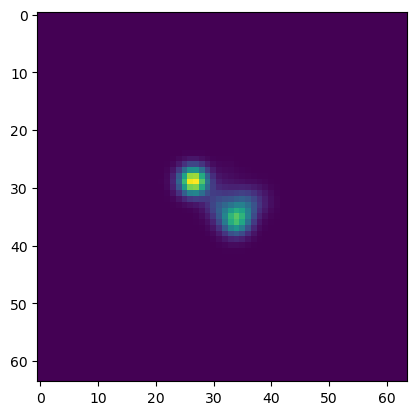

In [5]:
# just verify an image
plt.imshow(data_train[0,0,:,:,0,0])

In [6]:
# get the input device
#device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
#torch.cuda.empty_cache()

device = 'cpu' # for Apple Sillcon somehow not converging on my macboock M1 as compared to running with CPU
#print('Using device:', device)

print(f'Using device: {device}')
print(f'Data train shape: {data_train.shape}\nData verify shape: {data_verify.shape}')

Using device: cpu
Data train shape: (8, 4, 64, 64, 32, 36)
Data verify shape: (2, 4, 64, 64, 32, 36)


In [7]:
# make FluidDataset class:
class FluidDataset(Dataset):
    def __init__(self, data):
        self.data = data
        self.time_steps = self.data.shape[-1] # take first time step as "real" input ....
        self.n_samples = self.data.shape[0]
        print( "Numpy data shape: ",self.data.shape )

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        x_initial = self.data[idx,:,:,:,:,:1]  
        x = np.repeat(x_initial, self.time_steps-1, axis=-1) 
        y = self.data[idx,:,:,:,:,1:self.time_steps]  
        return {'x': torch.FloatTensor(x), 'y': torch.FloatTensor(y)}

    def values(self):
        return self.data.shape

dataset_train = FluidDataset(data_train)
dataset_test = FluidDataset(data_verify)

train_loader = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset_test, batch_size=batch_size, shuffle=False)

dataset_train[0]['x'].shape, dataset_train[0]['x'].shape, dataset_test[0]['y'].shape, dataset_train[0]['y'].shape
dataset_test.values(), dataset_train.values()
test_resolutions=[100]  #change later to real resiolution of the data ...
test_batch_sizes=[10]

# make test loaders dict
test_loaders = {}
for res, test_bsize in zip(test_resolutions, test_batch_sizes):
    print("res", res)
    test_loaders[res] = DataLoader(dataset_test, 
                                   batch_size=test_bsize,
                                    shuffle=False,
                                    num_workers=0,
                                    pin_memory=False,
                                   persistent_workers=False,)

gc.collect()
torch.mps.empty_cache()

Numpy data shape:  (8, 4, 64, 64, 32, 36)
Numpy data shape:  (2, 4, 64, 64, 32, 36)
res 100


In [8]:
# make the model and print the memory size of the model
model = FNO(
    in_channels=4,        # Input channels (e.g., velocity field)
    out_channels=4,       # Output channels
    n_modes=n_modes,   # [60,60,50],    # Number of modes in each layer
    hidden_channels=hidden_channels,   # 20             # Width of the network
    projection_channel_ratio=2
).to(device)

def calculate_model_memory(model):
    total_params = count_model_params(model) #sum(p.numel() for p in model.parameters())
    print(f'Total parameters: {total_params}')
    param_size = 4  # Size of a float32 in bytes
    total_memory = total_params * param_size  # Total memory in bytes

    # Convert to MB
    total_memory_MB = total_memory / (1024 ** 2)

    return total_memory_MB

memory_usage = calculate_model_memory(model)
print(f"Model memory usage: {memory_usage:.2f} MB")
log.write(f"Model memory usage: {memory_usage:.2f} MB\n")
log.close()


optimizer = AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)
# with changes to d=1 in loss functions input x=1 dim and y=10 dim works ... not sure if this is one wants to run it is spatial - temporal data ... !???
# looks like ouput prediction only 1 dim !??? Not clear what time step etc is predicted !???
# works with d=2 here too ... have to figure that out in more detail ...
l2loss = LpLoss(d=4, p=2)
h1loss = H1Loss(d=4)

train_loss = h1loss
eval_losses={'h1': h1loss, 'l2': l2loss}


#REMARKS: needs a bunch of more epochs to get the model to learn something useful ...
trainer = Trainer(model=model, n_epochs=n_epochs,
      device=device,
      wandb_log=False,
      eval_interval=2,
      use_distributed=False,
      verbose=True)

Total parameters: 301993652
Model memory usage: 1152.01 MB


In [9]:
# update the stub in the trainer to save outputs periodically
# trainer.save_dir = odir
# trainer.checkpoint_freq = checkpoint_freq
if checkpoint_freq is not None and checkpoint_freq > 0:
    def custom_on_epoch_start(self, epoch):
        # Call the original method if needed
        # super(type(self), self).on_epoch_start(epoch)
        # Add your additional functionality here
        # print(f"Custom on_epoch_start: Epoch {epoch}")
        # print(f'old epoch: {self.epoch}')
        self.epoch = epoch

        if self.epoch % checkpoint_freq == 0 and self.epoch > 0:
            save_dir = f'{odir}/checkpoint_{self.epoch}'
            if not os.path.exists(save_dir):
                os.makedirs(save_dir)
            self.checkpoint(save_dir)
            print('saving checkpoint to ', save_dir)

    trainer.on_epoch_start = custom_on_epoch_start.__get__(trainer, Trainer)


# set the logger and run training:
log_path = f'{odir}/training.log'

if log_directly:
    class Logger(object):
        def __init__(self, filename):
            self.terminal = sys.stdout
            self.log = open(filename, "w")
        def write(self, message):
            self.terminal.write(message)
            self.log.write(message)
        def flush(self):
            self.terminal.flush()
            self.log.flush()

    sys.stdout = Logger(log_path)

    def restore_stdout():
        sys.stdout.log.close()
        sys.stdout = sys.stdout.terminal
    atexit.register(restore_stdout)

trainer.train(train_loader=train_loader,
              test_loaders=test_loaders,
              optimizer=optimizer,
              scheduler=scheduler, 
              regularizer=False, 
              save_dir=odir,
              save_best='100_l2',
              training_loss=train_loss,
              eval_losses=eval_losses)

Training on 8 samples
Testing on [2] samples         on resolutions [100].


/opt/homebrew/Caskroom/miniconda/base/envs/fno_env_mlx/lib/python3.13/site-packages/torch/nn/modules/module.py:1791: UserWarning: FNO.forward() received unexpected keyword arguments: ['y']. These arguments will be ignored.
  return forward_call(*args, **kwargs)


Raw outputs of shape torch.Size([1, 4, 64, 64, 32, 35])


/Users/du8478/FNO/neuraloperator-4d-2.0.0/neuralop/training/trainer.py:536: UserWarning: H1Loss.__call__() received unexpected keyword arguments: ['x']. These arguments will be ignored.
  loss += training_loss(out, **sample)


[0] time=79.33, avg_loss=3.9688, train_err=3.9688
Eval: 100_h1=3.8952, 100_l2=3.9813


/Users/du8478/FNO/neuraloperator-4d-2.0.0/neuralop/training/trainer.py:581: UserWarning: LpLoss.__call__() received unexpected keyword arguments: ['x']. These arguments will be ignored.
  val_loss = loss(out, **sample)


[Rank 0]: saved training state to ./


{'train_err': 3.968837708234787,
 'avg_loss': 3.968837708234787,
 'avg_lasso_loss': None,
 'epoch_train_time': 79.32844495796598,
 '100_h1': tensor(3.8952),
 '100_l2': tensor(3.9813)}